# Week 7 — Kalman Filter Applied to Minute Bar Prices

**Course:** IEOR E4733 — Algorithmic Trading
**Reference:** *Machine Learning for Finance*, Ch. 4, pp. 100–103 (Jansen)

## Overview

This notebook demonstrates how to apply a **Kalman filter** to a single stock's
1-minute close price series, following the textbook example closely.

### Key Idea

Raw tick data is noisy. A Kalman filter extracts the underlying "true" price signal
by maintaining a **probabilistic estimate** of a hidden state that evolves over time.
Unlike a moving average with a fixed window, the Kalman filter:

- Adapts its window size implicitly, based on process and measurement noise parameters
- Propagates uncertainty (a covariance estimate) alongside the state estimate
- Updates recursively — O(1) per observation — so it works in real time

### Model (Univariate Random Walk + Noise)

| Component | Equation | pykalman parameter |
|-----------|----------|--------------------|
| State transition | $x_{t+1} = x_t + w_t,\quad w_t \sim \mathcal{N}(0, Q)$ | `transition_covariance` Q |
| Observation | $z_t = x_t + v_t,\quad v_t \sim \mathcal{N}(0, R)$ | `observation_covariance` R |

**Intuition:**
- Small Q → slow-moving true price (aggressive smoothing)
- Large Q → fast-changing true price (more responsive, less smoothed)
- Small R → trust observations heavily (filter tracks closely)
- Large R → distrust observations (filter smooths more aggressively)

### Two-Step Algorithm

1. **Predict:** $\hat{x}_{t|t-1} = x_{t-1}$, propagate uncertainty forward
2. **Update:** Weight prior estimate vs. new observation by their relative certainties (Kalman gain)


## 1. Imports

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pykalman import KalmanFilter

plt.rcParams.update({"figure.figsize": (14, 6), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 11})

BARS_H5    = Path("data/minute_bars.h5")
RESULTS_H5 = Path("data/kalman_results.h5")
SYMBOL     = "AAPL"

## 2. Load Minute Bars from HDF5

We source data from the HDF5 file produced by `minute_bars.py`.

In [2]:
with pd.HDFStore(str(BARS_H5), mode="r") as store:
    print("Available symbols:", store.keys())
    bars = store[f"minute_bars/{SYMBOL}"]

prices = bars["close"].dropna()
print(f"\nLoaded {len(prices)} minute bars for {SYMBOL}")
print(f"Session: {prices.index[0].strftime('%Y-%m-%d %H:%M')} → {prices.index[-1].strftime('%H:%M')}")
prices.describe().rename("close price").to_frame()

Available symbols: ['/minute_bars/AAPL', '/minute_bars/ABBV', '/minute_bars/ABT', '/minute_bars/ACN', '/minute_bars/ADBE', '/minute_bars/ADP', '/minute_bars/AMGN', '/minute_bars/AMT', '/minute_bars/AMZN', '/minute_bars/ANTM', '/minute_bars/AVGO', '/minute_bars/AXP', '/minute_bars/BA', '/minute_bars/BAC', '/minute_bars/BDX', '/minute_bars/BKNG', '/minute_bars/BLK', '/minute_bars/BMY', '/minute_bars/BNS', '/minute_bars/C', '/minute_bars/CAT', '/minute_bars/CB', '/minute_bars/CELG', '/minute_bars/CHTR', '/minute_bars/CI', '/minute_bars/CMCSA', '/minute_bars/CME', '/minute_bars/CNI', '/minute_bars/COST', '/minute_bars/CRM', '/minute_bars/CSCO', '/minute_bars/CVS', '/minute_bars/CVX', '/minute_bars/D', '/minute_bars/DHR', '/minute_bars/DIS', '/minute_bars/DUK', '/minute_bars/ENB', '/minute_bars/FB', '/minute_bars/FIS', '/minute_bars/FISV', '/minute_bars/GE', '/minute_bars/GILD', '/minute_bars/GOOG', '/minute_bars/GS', '/minute_bars/HD', '/minute_bars/HON', '/minute_bars/IBM', '/minute_bars/

,close price
count,390.000000
mean,242.615603
std,0.641130
min,241.290000
25%,242.070000
50%,242.565000
75%,243.087500
max,244.900000


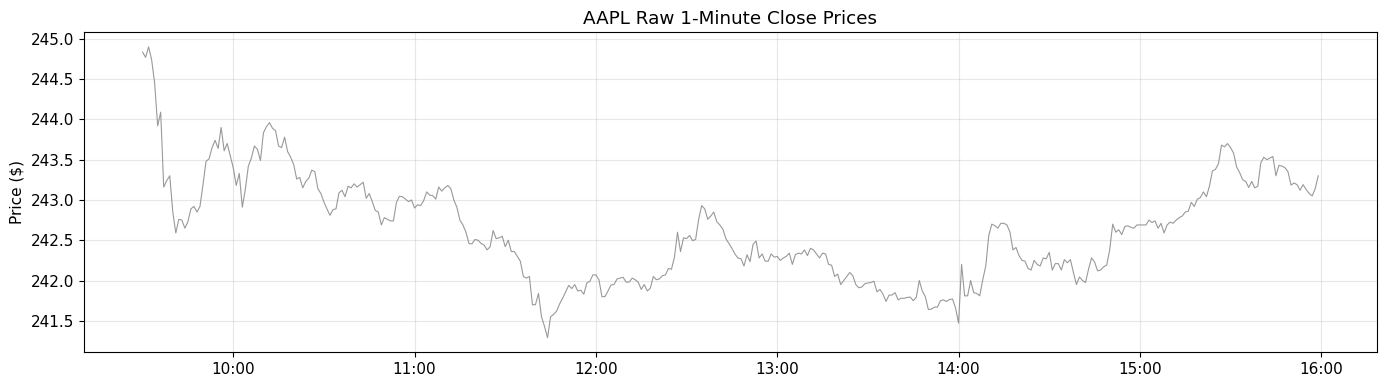

In [3]:
# Quick look at raw close prices
fig, ax = plt.subplots(figsize=(14,4))
ax.plot(prices.index, prices.values, lw=0.8, color="gray", alpha=0.8)
ax.set_title(f"{SYMBOL} Raw 1-Minute Close Prices")
ax.set_ylabel("Price ($)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
plt.tight_layout()
plt.show()

## 3. Kalman Filter — Textbook Example

Directly following the textbook (p. 102–103):

```python
kf = KalmanFilter(
    transition_matrices    = [1],
    observation_matrices   = [1],
    initial_state_mean     = prices.iloc[0],
    initial_state_covariance = 1,
    observation_covariance = 1,      # R
    transition_covariance  = 0.01,   # Q
)
state_means, _ = kf.filter(prices.values)
```

We set **R = 1** (moderate observation noise) and **Q = 0.01** (slow-changing true state).


In [5]:
prices.shape

(390,)

In [6]:
Q = 0.01   # transition covariance  (process noise)
R = 1.0    # observation covariance (measurement noise)

kf = KalmanFilter(
    transition_matrices      = [1],
    observation_matrices     = [1],
    initial_state_mean       = prices.iloc[0],
    initial_state_covariance = 1,
    observation_covariance   = R,
    transition_covariance    = Q,
)

state_means, state_covs = kf.filter(prices.values)

result = prices.to_frame("close")
result["kalman"]     = state_means.flatten()
result["kalman_std"] = np.sqrt(state_covs.flatten())

# Moving averages for comparison (20, 60, 120 minutes)
for w, col in [(20, "ma_20"), (60, "ma_60"), (120, "ma_120")]:
    result[col] = prices.rolling(window=w).mean()

result.head()

,close,kalman,kalman_std,ma_20,ma_60,ma_120
minute,,,,,,
2019-10-30 09:30:00,244.835,244.835000,0.707107,NaN,NaN,NaN
2019-10-30 09:31:00,244.770,244.813046,0.581161,NaN,NaN,NaN
2019-10-30 09:32:00,244.900,244.835482,0.507958,NaN,NaN,NaN
2019-10-30 09:33:00,244.740,244.815300,0.459750,NaN,NaN,NaN
2019-10-30 09:34:00,244.450,244.749091,0.425731,NaN,NaN,NaN


## 4. Visualise — Kalman Filter vs Moving Averages

Replicating Figure 4.6 from the textbook, adapted to minute bars.

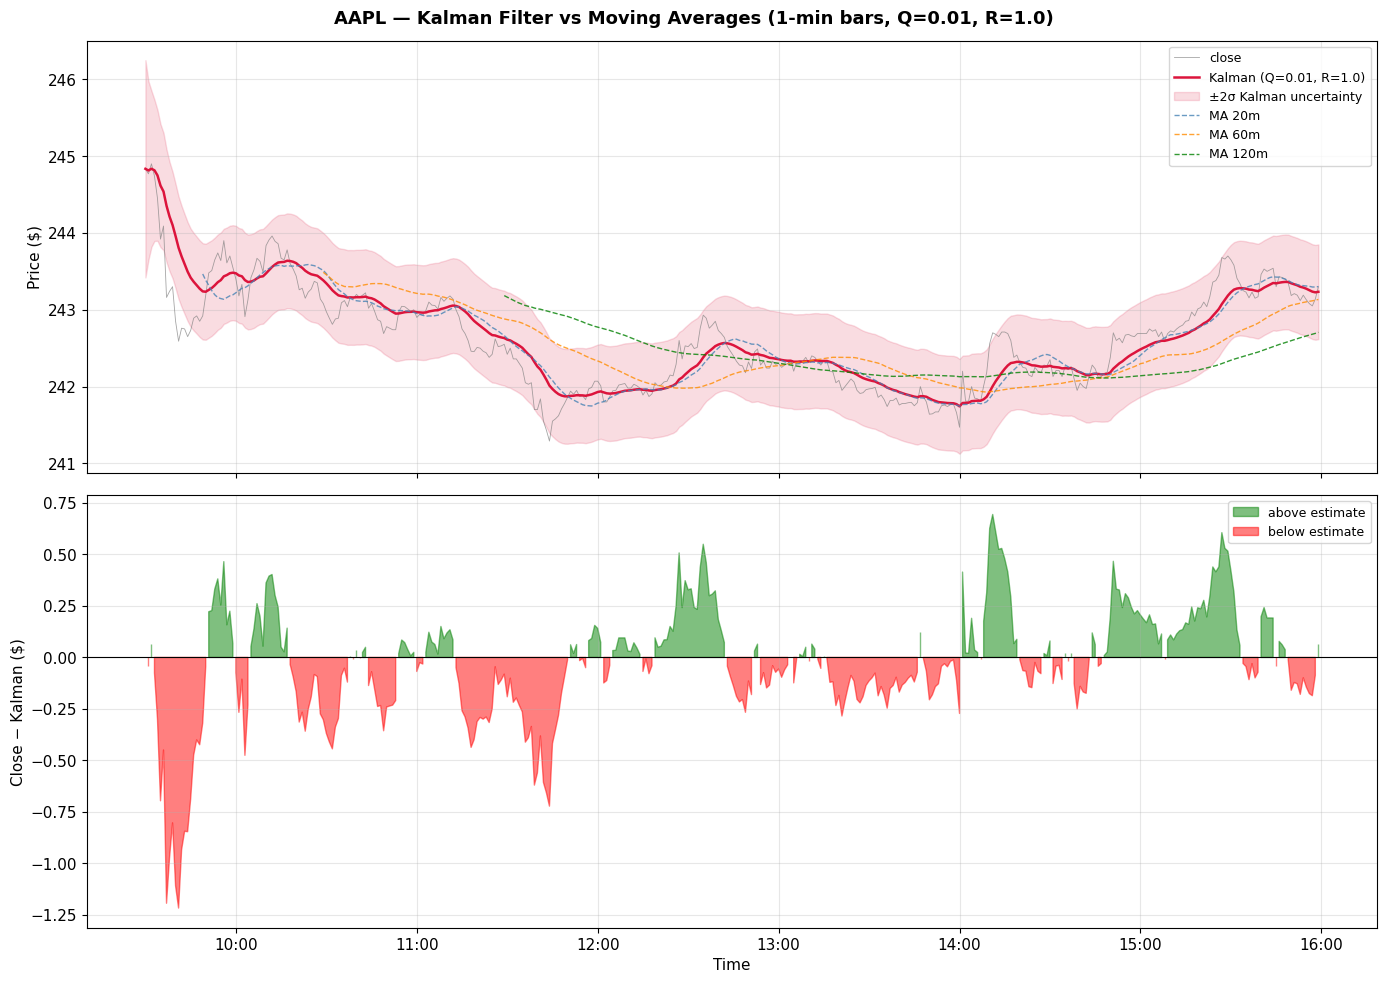

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
fig.suptitle(f"{SYMBOL} — Kalman Filter vs Moving Averages (1-min bars, Q={Q}, R={R})",
             fontsize=13, fontweight="bold")

# Panel 1: price + filter + MAs
ax = axes[0]
ax.plot(result.index, result["close"],   lw=0.6, color="gray",    alpha=0.7, label="close")
ax.plot(result.index, result["kalman"],  lw=1.8, color="crimson", label=f"Kalman (Q={Q}, R={R})")
ax.fill_between(result.index,
                result["kalman"] - 2 * result["kalman_std"],
                result["kalman"] + 2 * result["kalman_std"],
                alpha=0.15, color="crimson", label="±2σ Kalman uncertainty")
for col, color, label in [("ma_20","steelblue","MA 20m"),
                           ("ma_60","darkorange","MA 60m"),
                           ("ma_120","green","MA 120m")]:
    ax.plot(result.index, result[col], lw=1.0, color=color, linestyle="--", alpha=0.8, label=label)
ax.set_ylabel("Price ($)")
ax.legend(loc="upper right", fontsize=9)

# Panel 2: Kalman lag
ax = axes[1]
lag = result["close"] - result["kalman"]
ax.fill_between(result.index, 0, lag, where=(lag >= 0), color="green", alpha=0.5, label="above estimate")
ax.fill_between(result.index, 0, lag, where=(lag < 0),  color="red",   alpha=0.5, label="below estimate")
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Close − Kalman ($)")
ax.set_xlabel("Time")
ax.legend(loc="upper right", fontsize=9)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

plt.tight_layout()
plt.savefig(f"{SYMBOL}_kalman.png", dpi=150)
plt.show()

## 5. Kalman Smoother (Offline / Retrospective)

The **forward filter** above is causal — it only uses past observations.
The **smoother** does a second backward pass and gives a better retrospective estimate,
but cannot be used in real time.


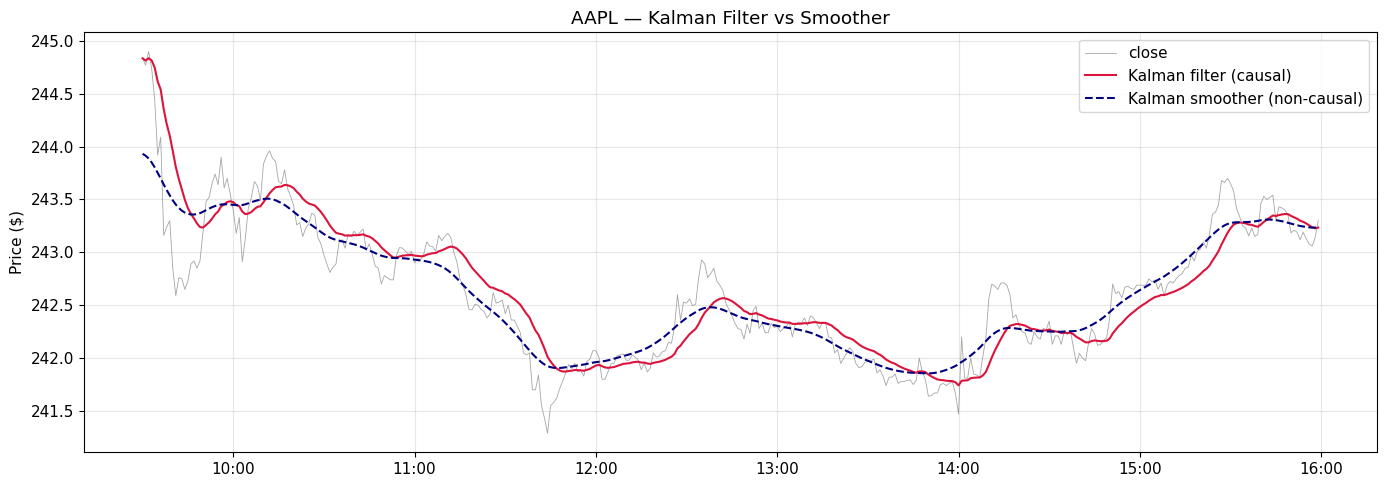

In [10]:
state_means_s, state_covs_s = kf.smooth(prices.values)

result["kalman_smooth"]     = state_means_s.flatten()
result["kalman_smooth_std"] = np.sqrt(state_covs_s.flatten())

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(result.index, result["close"],         lw=0.6, color="gray",    alpha=0.7, label="close")
ax.plot(result.index, result["kalman"],        lw=1.5, color="crimson", label="Kalman filter (causal)")
ax.plot(result.index, result["kalman_smooth"], lw=1.5, color="navy",    linestyle="--",
        label="Kalman smoother (non-causal)")
ax.set_title(f"{SYMBOL} — Kalman Filter vs Smoother")
ax.set_ylabel("Price ($)")
ax.legend(loc="upper right")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
plt.tight_layout()
plt.show()

## 6. Parameter Sensitivity — Q and R

The two key parameters control the trade-off between **responsiveness** and **smoothness**:

| Parameter | Effect when small | Effect when large |
|-----------|-------------------|-------------------|
| Q (process noise) | Slow-drifting state → aggressive smoothing | Fast-changing state → tracks closely |
| R (measurement noise) | Trust observations → tracks closely | Distrust observations → heavy smoothing |

The ratio **Q/R** determines the steady-state Kalman gain.


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)
fig.suptitle(f"{SYMBOL} — Kalman Filter Sensitivity to Q and R", fontsize=13, fontweight="bold")

configs = [(0.001, 1.0), (0.05, 1.0), (0.01, 0.1), (0.01, 5.0)]
labels  = ["Q=0.001 (very smooth)", "Q=0.05 (responsive)", "R=0.1 (trusts data)", "R=5.0 (heavy smooth)"]

for ax, (q, r), label in zip(axes.flat, configs, labels):
    kf_i = KalmanFilter(
        transition_matrices=[1], observation_matrices=[1],
        initial_state_mean=prices.iloc[0], initial_state_covariance=1,
        observation_covariance=r, transition_covariance=q,
    )
    sm, _ = kf_i.filter(prices.values)
    ax.plot(result.index, result["close"], lw=0.5, color="gray", alpha=0.6, label="close")
    ax.plot(result.index, sm.flatten(),    lw=1.5, color="crimson", label=f"Kalman")
    ax.set_title(label, fontsize=10)
    ax.legend(fontsize=8)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    for tick in ax.get_xticklabels():
        tick.set_rotation(30)

plt.tight_layout()
plt.show()

## 7. Statistics

In [ ]:
# Summarise filter quality
stats = pd.DataFrame({
    "mean_abs_lag":   (result["close"] - result["kalman"]).abs().mean(),
    "std_lag":        (result["close"] - result["kalman"]).std(),
    "corr_close":      result["close"].corr(result["kalman"]),
}, index=["Kalman filter"]).T

for w, col in [("MA 20m","ma_20"), ("MA 60m","ma_60"), ("MA 120m","ma_120")]:
    lag = result["close"] - result[col]
    stats[w] = [lag.abs().mean(), lag.std(), result["close"].corr(result[col])]

stats.round(4)

## 8. Save Results to HDF5

In [ ]:
RESULTS_H5.parent.mkdir(parents=True, exist_ok=True)

with pd.HDFStore(str(RESULTS_H5), mode="a", complevel=5, complib="blosc") as store:
    store.put(f"kalman/{SYMBOL}", result, format="table", data_columns=True)
    print(f"Saved to {RESULTS_H5}:/kalman/{SYMBOL}")
    print("Keys:", store.keys())

## Summary

| Concept | Description |
|---------|-------------|
| **State** $x_t$ | Hidden "true" price |
| **Observation** $z_t$ | Noisy close price |
| **Predict step** | $\hat{x}_{t\|t-1} = x_{t-1}$, variance $P_{t\|t-1} = P_{t-1} + Q$ |
| **Update step** | $K_t = P_{t\|t-1}/(P_{t\|t-1}+R)$, $\hat{x}_t = \hat{x}_{t\|t-1} + K_t(z_t - \hat{x}_{t\|t-1})$ |
| **Kalman gain** $K_t$ | Weights new observation vs prior; converges to $\sqrt{Q/R}$ in steady state |
| **Smoother** | Non-causal backward pass; retrospective only |

### Key Takeaways

1. The Kalman filter is more **adaptive** than a moving average — it responds faster when the signal changes.
2. Tuning Q and R is critical; a small Q/R ratio produces heavier smoothing.
3. In practice, parameters can be estimated by **EM** (available via `kf.em(prices.values, n_iter=10)`).
4. The filter naturally propagates **uncertainty** — the ±2σ band widens during volatile periods.
